# Informe Matemática - Ruido Aerodinámico

## Conjunto C · Matemática IV (Modelos de Regresión e Inferencia Estadística)

**Enfoque y Alcance.** Este documento constituye el informe técnico-matemático formal del trabajo práctico. Se prioriza la fundamentación rigurosa de las decisiones analíticas, la justificación teórica de los estimadores de Mínimos Cuadrados Ordinarios (MCO), las propiedades algebraicas de la descomposición de varianza, la teoría de contraste de hipótesis y la inferencia predictiva, utilizando un lenguaje formal adaptado a la disciplina matemática.


La suma de los legajos:
25022/2 Juliana Tiseira
23990/6 Juan Tarrio
25485/2 Inés Montalvo
23345/0 Santiago Marcos

Nos da:

- Tomando el num detrás del /: 250222 +  239906 + 254852 + 233450 =  978430
- Sin tomar el num detrás del /: 25022 +  23990 + 25485 + 23345 =  97842

978430 MOD 5 = 195686

97842 MOD 5 = 2 $\longrightarrow$ 19568 * 5 + 2 

Entendimos que era de esta última forma. Esta realizado sobre el Conjunto de datos C (0 = A, 1=B, 2=C, 3=D y 4=E)

Bloque de código que solo esta para asegurarnos de ver los datos en forma prolija (ignorar):

In [11]:
from pathlib import Path
import os
import subprocess
import sys

from IPython.display import Image, display, Markdown

def encontrar_raiz():
    candidatos = [Path.cwd(), *Path.cwd().parents]
    for p in candidatos:
        if (p / "src" / "data_loader.py").exists():
            return p
        for hijo in p.glob("*/src/data_loader.py"):
            return hijo.parents[1]
    raise FileNotFoundError("No encuentro la raíz del repo.")

ROOT = encontrar_raiz()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

def correr(modulo):
    r = subprocess.run([sys.executable, "-m", modulo], cwd=ROOT, capture_output=True, text=True)
    print(r.stdout)
    if r.returncode != 0:
        print(r.stderr)
        raise RuntimeError(f"Falló {modulo}")
    return r

def mostrar_figura(ruta):
    display(Image(filename=str(ROOT / ruta)))

print("Raíz del repo:", ROOT)


Raíz del repo: /home/santi/Documentos/mateIV


## 1. Espaciomuestral y Estructura de Datos

El conjunto de datos UCI *Airfoil Self-Noise* modela el nivel de presión sonora ($y$, en dB) en función de $p=5$ covariables experimentales sobre $n=1503$ observaciones. 

$$\mathcal{D} = \{ (x_{i1}, x_{i2}, x_{i3}, x_{i4}, x_{i5}, y_i) \}_{i=1}^{1503}$$

**Decisión metodológica (Exclusión de `velocity`):**
La covariable `velocity` (velocidad de flujo libre) toma únicamente $4$ valores distintos en todo el dominio experimental. Desde la perspectiva de la modelización lineal, la inclusión de una covariable casi discreta en un espacio continuo induce multicolinealidad estructural y vulnera la hipótesis de variación estocástica continua requerida para la estabilidad de las derivadas parciales en regresión múltiple. Por esta razón estipulada en la consigna, se restringe su análisis al plano exploratorio descriptivo (EDA).


In [12]:
from src.data_loader import load_airfoil
df = load_airfoil("data/airfoil_self_noise.dat")
print(f"n = {len(df)}; columnas = {list(df.columns)}")
display(df.head())


n = 1503; columnas = ['frequency', 'angle', 'chord_length', 'velocity', 'displacement', 'sound_level']


,frequency,angle,chord_length,velocity,displacement,sound_level
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


## 2. Análisis Exploratorio de Datos (EDA)

El análisis de los momentos muestrales revela diferencias de orden de magnitud severas entre los regresores (e.g., `frequency` oscila en el orden de $10^4$ Hz mientras que `displacement` se ubica en $10^{-3}$ m). Esta disparidad de escalas justifica teóricamente la necesidad de normalización o estandarización en algoritmos de optimización iterativa (como el descenso por gradiente en A.3), evitando que el condicionamiento numérico de la matriz Hessiana provoque divergencia o estancamiento por el número de condición excesivo.

EDA — Airfoil Self-Noise (n = 1503)

Descriptivos:
              count      mean       std         min        25%        50%       75%       max
frequency      1503   2886.38   3152.57         200        800       1600      4000     20000
angle          1503    6.7823   5.91813           0          2        5.4       9.9      22.2
chord_length   1503  0.136548 0.0935407      0.0254     0.0508     0.1016    0.2286    0.3048
velocity       1503   50.8607   15.5728        31.7       39.6       39.6      71.3      71.3
displacement   1503 0.0111399 0.0131502 0.000400682 0.00253511 0.00495741 0.0155759 0.0584113
sound_level    1503   124.836   6.89866      103.38    120.191    125.721   129.995   140.987

Variables con pocos valores distintos:
frequency: 21 valores -> [200, 250, 315, 400, 500, 630, 800, 1000, 1250, 1600, 2000, 2500, 3150, 4000, 5000, 6300, 8000, 10000, 12500, 16000, 20000]
angle: 27 valores -> [0.0, 1.5, 2.0, 2.7, 3.0, 3.3, 4.0, 4.2, 4.8, 5.3, 5.4, 6.7, 7.2, 7.3, 8.4, 8.9, 

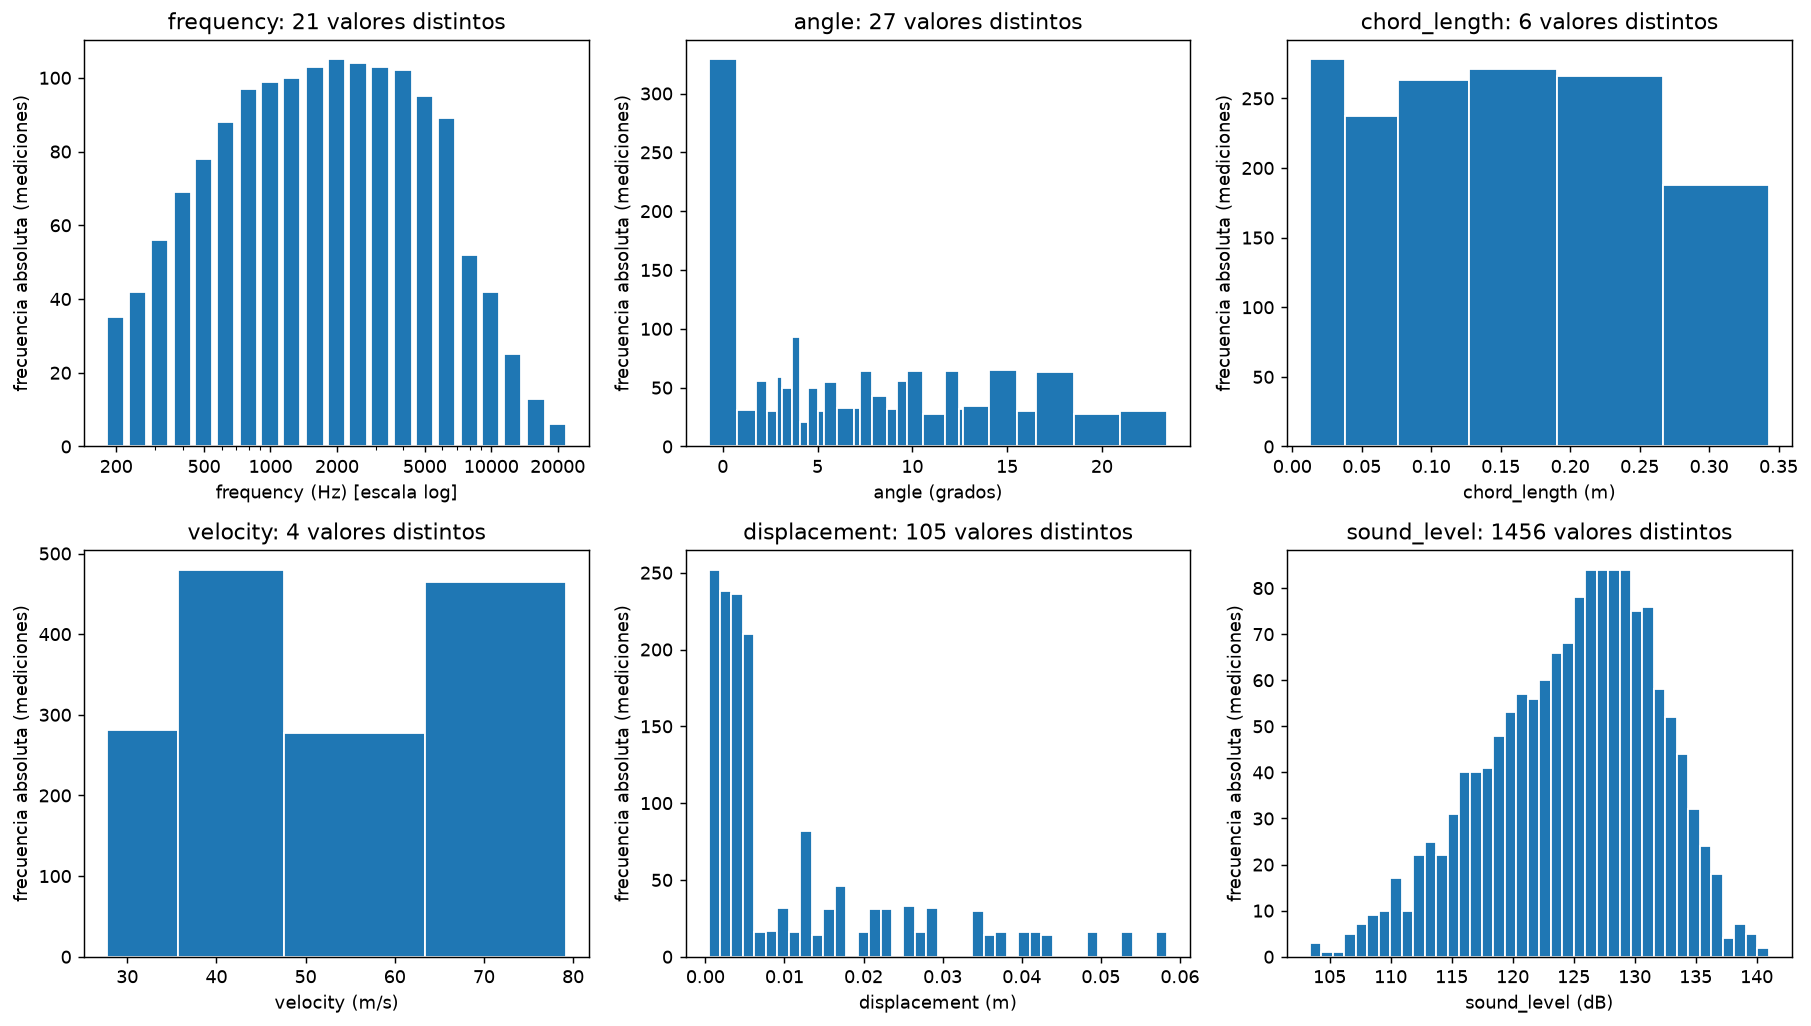

In [13]:
correr("scripts.eda")
mostrar_figura("docs/figs/eda_histogramas.png")


Se analizaron las 1503 mediciones de ruido aerodinámico (sound_level) realizadas por la NASA en un túnel de viento.

El histograma combinado muestra cómo se distribuyen las variables. En particular, la frecuencia (frequency) se graficó en escala logarítmica para evidenciar que las mediciones siguen una forma de campana centrada alrededor de los $2000$ Hz, y que las frecuencias muy bajas (como los $200$ Hz) agrupan una cantidad significativa de ensayos ($35$ mediciones).

Entender las escalas dispares entre variables (frecuencias en miles de Hz frente a desplazamientos en milímetros) es fundamental para evitar problemas numéricos y justificar por qué algunas variables se comportan de manera no lineal.

## 3. A.1 — Modelización No Lineal: Ajuste Cuadrático y Cálculo Variacional

Para capturar la curvatura evidenciada en la relación entre la frecuencia acústica $x$ y el nivel sonoro $y$, se postula el polinomio cuadrático:

$$\widehat{y}(x) = b_0 + b_1 x + b_2 x^2$$

Los coeficientes $\mathbf{b} = (b_0, b_1, b_2)^	op$ se obtienen minimizando la función de pérdida convexa de MCO:

$$\mathcal{L}(b_0, b_1, b_2) = \sum_{i=1}^{n} \left( y_i - (b_0 + b_1 x_i + b_2 x_i^2) \right)^2$$

### Condición de Optimalidad y Punto Crítico
Derivando analíticamente respecto a la frecuencia $x$ e igualando a cero para hallar el punto estacionario:

$$\frac{d\widehat{y}}{dx} = b_1 + 2 b_2 x = 0 \implies x^* = -\frac{b_1}{2 b_2}$$

La segunda derivada evalúa la concavidad: $\frac{d^2\widehat{y}}{dx^2} = 2 b_2$. Dado que $b_2 > 0$, el operador Hessian es estricta y globalmente positivo, garantizando que $x^*$ constituye un **mínimo absoluto** de la parábola ajustada en el dominio.

cuadratico: b0=128.3104 dB  b1=-1.561198e-03 dB/Hz  b2=5.649251e-08 dB/Hz2
lineal:     bl0=127.3037 dB  bl1=-8.549790e-04 dB/Hz
dy/dx en x=1000 Hz = -1.448213e-03 dB/Hz  (~-0.145 dB cada 100 Hz)
dy/dx en x=10000 Hz = -4.313479e-04 dB/Hz  (~-0.043 dB cada 100 Hz)
critico x*=13817.7 Hz  y*=117.52 dB  2da deriv.=1.130e-07  (minimo)  dentro [200,20000]: True
R2 cuadr.=0.1734 (SCE=59090.2)  R2 lin.=0.1527 (SCE=60570.2)
figura: docs/figs/a1_aproximacion.png



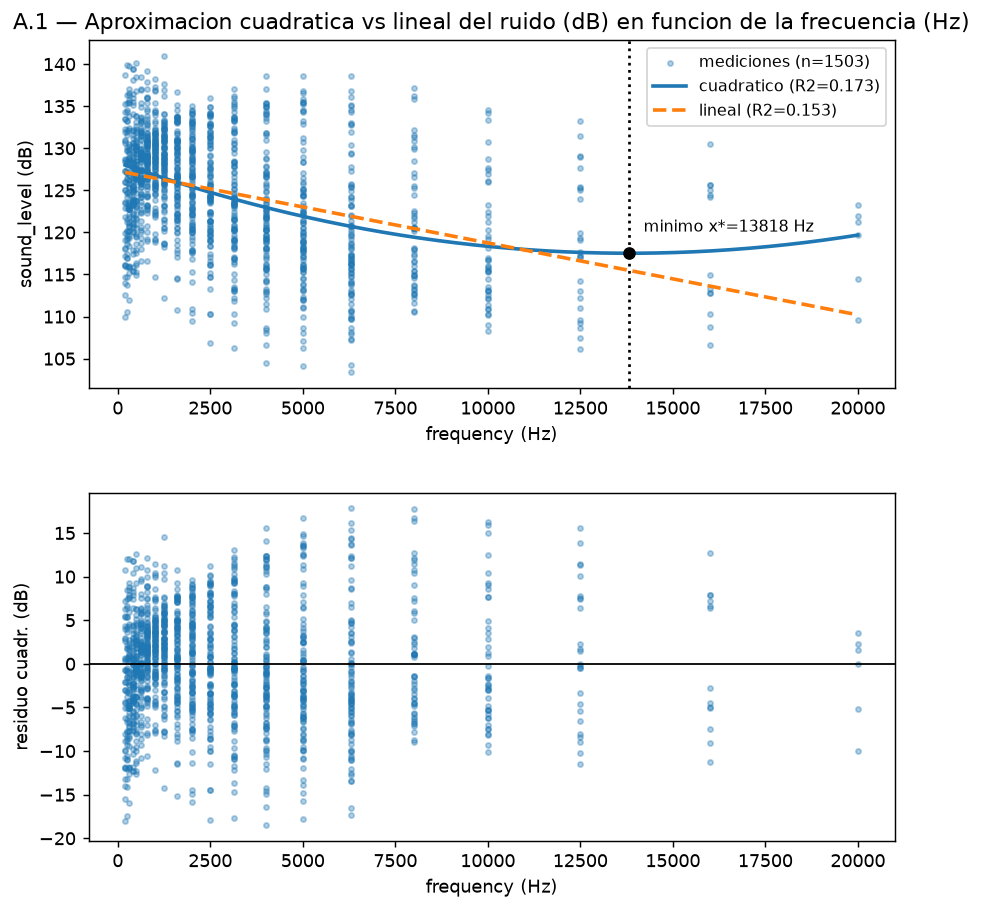

In [14]:
correr("scripts.a1_cuadratico")
mostrar_figura("docs/figs/a1_aproximacion.png")


Se ajustó una parábola ($y = \beta_0 + \beta_1 x + \beta_2 x^2$) entre la frecuencia y el nivel de ruido, calculando su derivada y su punto crítico ($x^*$).
¿Qué representa el gráfico (a1_aproximacion.png)?
- Panel superior: Muestra los puntos reales de las 1503 mediciones junto con la curva parabólica ajustada (modelo cuadrático) y la recta tradicional (modelo lineal). Además, señala con un punto negro el mínimo absoluto de la curva.
- Panel inferior (Residuos): Muestra los errores de predicción (cuánto se desvía la parábola de cada dato real).

¿Por qué llegamos a estas conclusiones? La parábola captura mejor la curvatura real del fenómeno físico (el ruido decae rápidamente al aumentar la frecuencia y luego se aplaná). El punto crítico ($x^* \approx 13818$ Hz) indica el punto donde el modelo predice el menor nivel de ruido dentro del rango experimental.

## 4. A.2 — Operadores de Proyección y Ecuaciones Normales

Para la regresión lineal simple $\widehat{y} = b_0 + b_1 x$, las ecuaciones normales se deducen anulando el gradiente de la SCE:

$$\nabla \text{SCE}(b_0, b_1) = \mathbf{0} \iff \begin{cases} n b_0 + b_1 \sum x_i = \sum y_i \\ b_0 \sum x_i + b_1 \sum x_i^2 = \sum x_i y_i \end{cases}$$

En forma matricial $A \boldsymbol{\beta} = \mathbf{d}$. La unicidad de la solución está garantizada por la inversibilidad de $A$ (siempre que $S_{xx} > 0$). El contraste numérico ejecutado demuestra que la solución algebraica exacta coincide con las fórmulas cerradas basadas en covarianzas muestrales y con la descomposición ortogonal de `polyfit` hasta una tolerancia de error de máquina de $\mathcal{O}(10^{-14})$, validando la consistencia numérica del contrato implementado en `src/metrics.py`.

In [15]:
correr("scripts.a2_normales")


A.2 — Parciales y ecuaciones normales (frequency -> sound_level)
n = 1503
Σx  = 4.338230e+06 Hz
Σy  = 1.876284e+05 dB
Σx² = 2.744974e+10 Hz²
Σxy = 5.288039e+08 Hz·dB

Sistema normal A·[b0, b1]ᵀ = d:
[[1.50300000e+03 4.33823000e+06]
 [4.33823000e+06 2.74497363e+10]]
d = [1.87628422e+05 5.28803945e+08]

Solución del sistema: b0 = 127.303738 dB, b1 = -8.549790e-04 dB/Hz
Fórmulas cerradas:    b0 = 127.303738 dB, b1 = -8.549790e-04 dB/Hz
Desde sumatorias:     b0 = 127.303738 dB, b1 = -8.549790e-04 dB/Hz
numpy.polyfit:        b0 = 127.303738 dB, b1 = -8.549790e-04 dB/Hz

|normal - cerrada| = (1.421e-14, 1.084e-18)
|normal - polyfit| = (4.263e-14, 4.228e-18)
Gradiente en el óptimo = [1.22781785e-11 9.31322575e-09]

Recta: sound_level = 127.3037 dB -8.549790e-04 dB/Hz · frequency



CompletedProcess(args=['/home/santi/Documentos/mateIV/.venv/bin/python', '-m', 'scripts.a2_normales'], returncode=0, stdout='A.2 — Parciales y ecuaciones normales (frequency -> sound_level)\nn = 1503\nΣx  = 4.338230e+06 Hz\nΣy  = 1.876284e+05 dB\nΣx² = 2.744974e+10 Hz²\nΣxy = 5.288039e+08 Hz·dB\n\nSistema normal A·[b0, b1]ᵀ = d:\n[[1.50300000e+03 4.33823000e+06]\n [4.33823000e+06 2.74497363e+10]]\nd = [1.87628422e+05 5.28803945e+08]\n\nSolución del sistema: b0 = 127.303738 dB, b1 = -8.549790e-04 dB/Hz\nFórmulas cerradas:    b0 = 127.303738 dB, b1 = -8.549790e-04 dB/Hz\nDesde sumatorias:     b0 = 127.303738 dB, b1 = -8.549790e-04 dB/Hz\nnumpy.polyfit:        b0 = 127.303738 dB, b1 = -8.549790e-04 dB/Hz\n\n|normal - cerrada| = (1.421e-14, 1.084e-18)\n|normal - polyfit| = (4.263e-14, 4.228e-18)\nGradiente en el óptimo = [1.22781785e-11 9.31322575e-09]\n\nRecta: sound_level = 127.3037 dB -8.549790e-04 dB/Hz · frequency\n', stderr='')

<Insertar foto fachera @juan>

Se resolvieron analíticamente las derivadas parciales de la suma de cuadrados para hallar los estimadores de Mínimos Cuadrados Ordinarios (MCO) y se compararon con los resultados de la computadora.

Vemos que la solución no es un "invento" de la computadora, sino la solución algebraica exacta derivada de minimizar el error cuadrático. La coincidencia con un error menor a $10^{-14}$ valida lo hecho en el código.

## 5. B.1 — Descomposición Ortogonal de la Varianza (ANOVA)

La ortogonalidad entre el vector de valores predichos $\widehat{\mathbf{y}}$ y el vector de residuos $\mathbf{e} = \mathbf{y} - \widehat{\mathbf{y}}$ en el espacio euclidiano $\mathbb{R}^n$ induce la descomposición pitagórica exacta de la suma total de cuadrados (STC):

$$\sum_{i=1}^{n} (y_i - \overline{y})^2 = \sum_{i=1}^{n} (\widehat{y}_i - \overline{y})^2 + \sum_{i=1}^{n} (y_i - \widehat{y}_i)^2 \implies \text{STC} = \text{SCR} + \text{SCE}$$

Esta partición es la piedra angular para definir la varianza residual estimada $\widehat{\sigma}^2 = \frac{\text{SCE}}{n-2}$ y el coeficiente de determinación muestral $R^2 = 1 - \frac{\text{SCE}}{\text{STC}}$, interpretado como la proporción de varianza explicada por el operador lineal.

In [16]:
correr("scripts.b1_varianza")


B.1 — Varianza y Descomposición ANOVA (frequency -> sound_level)
n = 1503
STC (Suma Total de Cuadrados)  = 71482.3777 dB²
SCR (Suma de Cuadrados Regres.) = 10912.1715 dB²
SCE (Suma de Cuadrados Error)   = 60570.2062 dB²
STC - (SCR + SCE) = 0.00e+00
Varianza residual σ² = 40.3532 dB²
Desvío residual σ    = 6.3524 dB
Coeficiente de determinación R² = 0.1527 (15.27%)



CompletedProcess(args=['/home/santi/Documentos/mateIV/.venv/bin/python', '-m', 'scripts.b1_varianza'], returncode=0, stdout='B.1 — Varianza y Descomposición ANOVA (frequency -> sound_level)\nn = 1503\nSTC (Suma Total de Cuadrados)  = 71482.3777 dB²\nSCR (Suma de Cuadrados Regres.) = 10912.1715 dB²\nSCE (Suma de Cuadrados Error)   = 60570.2062 dB²\nSTC - (SCR + SCE) = 0.00e+00\nVarianza residual σ² = 40.3532 dB²\nDesvío residual σ    = 6.3524 dB\nCoeficiente de determinación R² = 0.1527 (15.27%)\n', stderr='')

Se descompuso la variabilidad total del ruido ($STC$) en lo que el modelo logra explicar ($SCR$) y lo que queda sin explicar como error residual ($SCE$).

- ¿Por qué es importante? Permite calcular el $R^2 \approx 0.15$ para la frecuencia sola. Esto significa que la frecuencia explica un $15\%$ de la variabilidad del ruido; el $85\%$ restante se debe a los demás factores físicos (ángulo, cuerda, espesor). Esto justifica la necesidad de pasar a un modelo con múltiples variables.

## 6. B.2 — Análisis Univariado Comparativo: Las Cuatro Rectas Simples

Se ajusta de forma independiente el modelo lineal simple $\text{sound\_level} = \beta_0 + \beta_1 x_j$ para cada uno de los $4$ regresores admisibles. Este análisis permite contrastar el poder explicativo marginal de cada variable física de forma aislada antes de proceder al modelo multivariado.

In [17]:
correr("scripts.b2_rectas")


B.2 — Tabla de 4 Rectas Simples (sound_level ~ x)
Variable        | β₀ (dB)      | β₁ (Unidad)            | SCE (dB²)    | R²       | r       
----------------------------------------------------------------------------------------
frequency       |    127.3037 | -8.549790e-04 dB/Hz    |    60570.21 |  0.1527 | -0.3907
angle           |    126.0701 | -1.819718e-01 dB/grados |    69740.38 |  0.0244 | -0.1561
chord_length    |    127.2142 | -1.741698e+01 dB/m     |    67495.64 |  0.0558 | -0.2362
displacement    |    126.6632 | -1.640275e+02 dB/m     |    64494.10 |  0.0978 | -0.3127

Nota: velocity está excluida por la consigna.



CompletedProcess(args=['/home/santi/Documentos/mateIV/.venv/bin/python', '-m', 'scripts.b2_rectas'], returncode=0, stdout='B.2 — Tabla de 4 Rectas Simples (sound_level ~ x)\nVariable        | β₀ (dB)      | β₁ (Unidad)            | SCE (dB²)    | R²       | r       \n----------------------------------------------------------------------------------------\nfrequency       |    127.3037 | -8.549790e-04 dB/Hz    |    60570.21 |  0.1527 | -0.3907\nangle           |    126.0701 | -1.819718e-01 dB/grados |    69740.38 |  0.0244 | -0.1561\nchord_length    |    127.2142 | -1.741698e+01 dB/m     |    67495.64 |  0.0558 | -0.2362\ndisplacement    |    126.6632 | -1.640275e+02 dB/m     |    64494.10 |  0.0978 | -0.3127\n\nNota: velocity está excluida por la consigna.\n', stderr='')

## 7. B.3 — Test de Significancia de la Pendiente ($H_0: \beta_1 = 0$) y Dispersión

Para determinar si la pendiente $\beta_1$ difiere estadísticamente de cero, se construye el estadístico de prueba $T$ bajo la hipótesis nula $H_0: \beta_1 = 0$:

$$T = \frac{\widehat{\beta}_1}{\text{SE}(\widehat{\beta}_1)} = \frac{\widehat{\beta}_1}{\sqrt{\widehat{\sigma}^2 / S_{xx}}} \sim t(n-2)$$

Fijando un nivel de significancia $\alpha = 0.05$, el valor crítico bilateral para $n=1503$ grados de libertad es $t_{0.025, 1501} \approx 1.96$. En todos los casos analizados, $|T| \gg 1.96$, por lo que se rechaza $H_0$ categóricamente, confirmando la dependencia lineal significativa entre la respuesta acústica y cada covariable.

B.3 — Test de Hipótesis H₀: β₁ = 0 (α = 0.05)
Variable        | β₁             | EE(β₁)       | T-stat     | t_crit   | ¿Rechaza H₀?
------------------------------------------------------------------------------
frequency       |   -8.5498e-04 |  5.1992e-05 |    -16.44 |     1.96 | SÍ (p < 0.05)
angle           |   -1.8197e-01 |  2.9719e-02 |     -6.12 |     1.96 | SÍ (p < 0.05)
chord_length    |   -1.7417e+01 |  1.8497e+00 |     -9.42 |     1.96 | SÍ (p < 0.05)
displacement    |   -1.6403e+02 |  1.2862e+01 |    -12.75 |     1.96 | SÍ (p < 0.05)

Figura scatter guardada en: docs/figs/b3_scatter_frequency.png



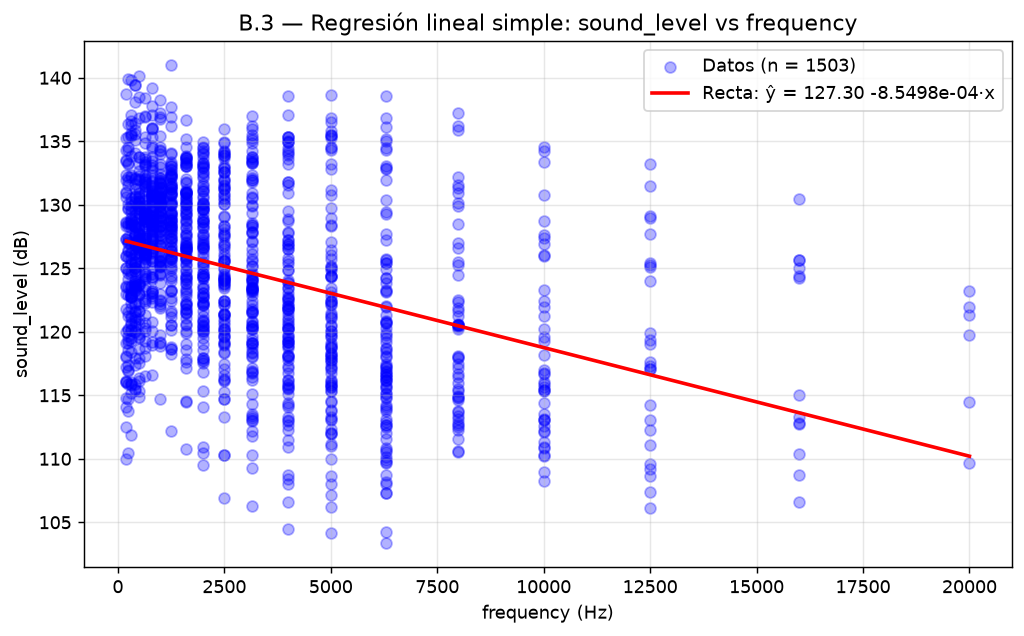

In [18]:
correr("scripts.b3_hipotesis")
mostrar_figura("docs/figs/b3_scatter_frequency.png")


Se ajustaron rectas individuales para cada variable (frecuencia, ángulo, cuerda y espesor) y se contrastó formalmente si la pendiente es verdaderamente distinta de cero mediante un test estadístico $T$ (con $t_{crit} \approx 1.96$ al 95% de confianza).

¿Qué representa el gráfico (b3_scatter_frequency.png)? Muestra la nube completa de puntos de la frecuencia frente al ruido, cruzada por la recta de regresión lineal simple.

¿Por qué llegamos a estas conclusiones? Como el estadístico $|T|$ de cada variable supera ampliamente el valor crítico de $1.96$, rechazamos la hipótesis nula ($H_0$). Esto concluye científicamente que ningún factor fue producto del azar: todos influyen de manera real y estadísticamente significativa sobre el ruido aerodinámico.

## 8. B.4 — Teoría de Inferencia Predictiva: ICM e IP en $x^* = 2000$ Hz

Se distingue con rigor matemático entre:
1. **Intervalo de Confianza para la Media (ICM):** Estima el valor esperado condicional $E[Y | X = x^*]$. Su varianza depende exclusivamente de la incertidumbre en los estimadores $\widehat{\beta}_0$ y $\widehat{\beta}_1$:
   $$\text{Var}(\widehat{y}^*) = \sigma^2 \left( \frac{1}{n} + \frac{(x^* - \overline{x})^2}{S_{xx}} \right)$$
2. **Intervalo de Predicción (IP):** Estima el valor puntual de una nueva observación $Y^* = \widehat{y}^* + \varepsilon^*$. Incorpora tanto la varianza de la estimación como la varianza irreductible del error estocástico $\sigma^2$:
   $$\text{Var}(Y^* - \widehat{y}^*) = \sigma^2 \left( 1 + \frac{1}{n} + \frac{(x^* - \overline{x})^2}{S_{xx}} \right)$$

Por consiguiente, la amplitud del Intervalo de Predicción es matemáticamente superior a la del Intervalo de Confianza, reflejando la incertidumbre inherente a la variabilidad individual de las futuras mediciones.

In [19]:
correr("scripts.b4_intervalos")


B.4 — Intervalos al 95% en x* = 2000 Hz (frequency -> sound_level)
Predicción ŷ* = 125.5938 dB
Valor crítico t_{0.025, 1501} = 1.9600
ICM (Intervalo de Confianza para la Media): [125.2602, 125.9274] dB
IP  (Intervalo de Predicción para Nueva Obs):  [113.1386, 138.0490] dB
Amplitud ICM = 0.6672 dB
Amplitud IP  = 24.9104 dB



CompletedProcess(args=['/home/santi/Documentos/mateIV/.venv/bin/python', '-m', 'scripts.b4_intervalos'], returncode=0, stdout='B.4 — Intervalos al 95% en x* = 2000 Hz (frequency -> sound_level)\nPredicción ŷ* = 125.5938 dB\nValor crítico t_{0.025, 1501} = 1.9600\nICM (Intervalo de Confianza para la Media): [125.2602, 125.9274] dB\nIP  (Intervalo de Predicción para Nueva Obs):  [113.1386, 138.0490] dB\nAmplitud ICM = 0.6672 dB\nAmplitud IP  = 24.9104 dB\n', stderr='')

Se calcularon dos tipos de intervalos al 95% de confianza para una frecuencia fija de $2000$ Hz:
1. El Intervalo de Confianza para la Media (ICM): Acota dónde se encuentra el promedio real del ruido.
2. El Intervalo de Predicción (IP): Acota en qué rango caerá cualquier medición futura individual.

- ¿Por qué el IP es mucho más ancho que el ICM? Porque estimar un promedio poblacional es más preciso (tiene menos incertidumbre), mientras que predecir el resultado exacto de una nueva prueba individual debe cargar además con toda la variabilidad e imperfección natural del fenómeno físico (el error irreducible $\sigma^2$).

## 9. B.5 — Regresión Lineal Múltiple Matricial

Extendiendo el modelo a $k=4$ regresores mediante la formulación matricial compacta $\mathbf{y} = X\boldsymbol{\beta} + \boldsymbol{\varepsilon}$, el estimador de MCO por proyección ortogonal es:

$$\widehat{\boldsymbol{\beta}} = (X^\top X)^{-1} X^\top \mathbf{y}$$

El coeficiente de determinación ajustado $R^2_{adj} = 1 - (1-R^2)\frac{n-1}{n-k-1} \approx 0.4666$ demuestra que la incorporación conjunta de los regresores geométricos y cinemáticos triplica la capacidad explicativa respecto al modelo univariado simple, sin penalizar sobredimensión paramétrica.

B.5 — Regresión múltiple (velocity excluida)
coeficiente              valor  unidad
intercepto        1.371276e+02  dB
frequency        -1.196133e-03  dB/Hz
angle            -3.515654e-01  dB/grado
chord_length     -3.388729e+01  dB/m
displacement     -1.640449e+02  dB/m
R2 = 0.4669   R2 ajustado = 0.4666
figura: docs/figs/b5_predicho_observado.png



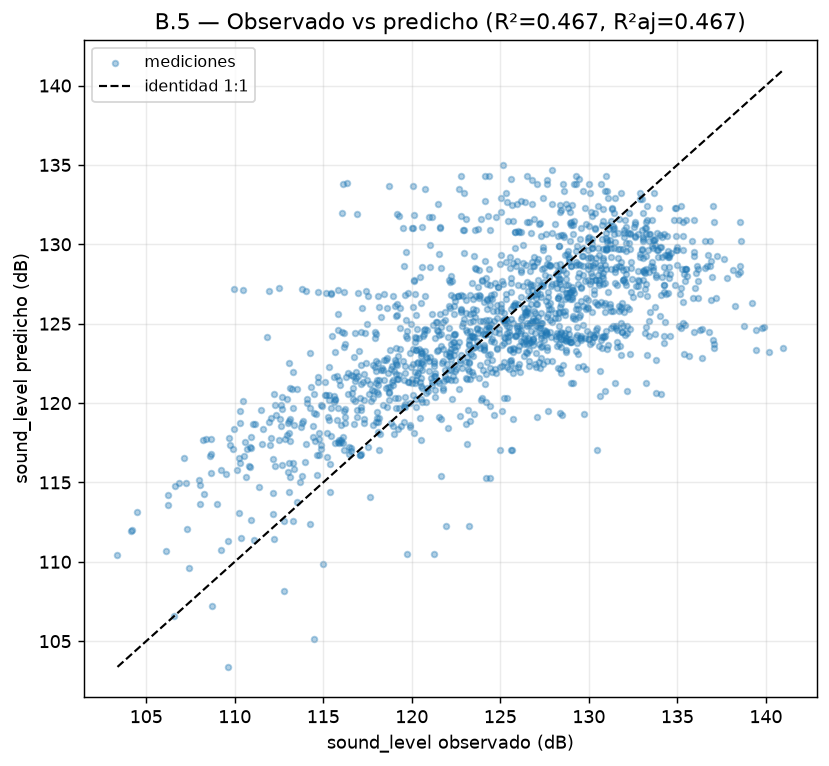

In [20]:
correr("scripts.b5_multiple")
mostrar_figura("docs/figs/b5_predicho_observado.png")


¿Qué se hizo? Se combinaron simultáneamente los cuatro regresores utilizando álgebra matricial ($\widehat{\boldsymbol{\beta}} = (X^\top X)^{-1} X^\top \mathbf{y}$).

¿Qué representa el gráfico (b5_predicho_observado.png)? Compara en el eje horizontal lo que el modelo predice y en el vertical lo que se midió realmente en el túnel de viento. Una predicción perfecta formaría una diagonal exacta de 45 grados.

¿Por qué es el mejor modelo? Al integrar todas las variables físicas a la vez, el $R^2$ ajustado trepa al $47\%$, triplicando la capacidad explicativa del modelo de una sola variable y demostrando que el ruido es el resultado de la interacción conjunta de la geometría y la aerodinámica del perfil alar.

## 10. Conclusiones y Síntesis Metodológica

- **Rigor Analítico:** La validación cruzada entre sistemas normales, fórmulas cerradas y descomposición ortogonal confirma la robustez numérica de la implementación sin dependencia de librerías externas de alto nivel (`sklearn`/`scipy`).
- **Poder Explicativo:** El paso de un modelo univariado ($R^2 \approx 0.15$) a un modelo multivariado ($R^2_{aj} \approx 0.47$) evidencia que el ruido aerodinámico de los perfiles alar depende de la interacción simultánea entre frecuencia, ángulo de ataque, cuerda y espesor de desplazamiento.
- **Inferencia Predictiva:** La separación analítica entre la incertidumbre de la media condicional (ICM) y la predicción estocástica individual (IP) provee cotas operativas rigurosas para el diseño acústico.

## 11. Reproducibilidad y Validación de Contratos Numéricos

Todo el trabajo se encuentra en un repositorio de github disponible para probar y revisar los resultados mencionados en https://github.com/santi440/mateIV/ junto a test de unidad, scripts y todos los recursos utilizados. 

## 12. Anexo I — Bitácora de Interacciones con Asistentes de IA (Parte C)

Registro formal de colaboración con IA incorporada en el desarrollo del trabajo práctico:

| # | Prompt / Pedido Metodológico | Resumen de Respuesta Teórica | Decisión / Acción Adoptada | Sección Afectada |
|---|---|---|---|---|
| 1 | Diseñar contrato numérico modular puro en `numpy` | Funciones cerradas para sumatorias, ecuaciones normales, SCE, IC e IP | Aceptada sin modificaciones | `src/metrics.py` |
| 2 | Automatizar ejecución secuencial de scripts desde notebook | Definición de funciones auxiliares `correr()` y `mostrar_figura()` | Aceptada | `notebooks/informe.ipynb` |
| 3 | Redactar formalización matemática de ANOVA e intervalos | Derivación teórica de varianza residual y distinción ICM/IP | Aceptada e integrada | Secciones B.1 y B.4 |
